# Statistical testing in the software lifecycle

This block applies the tests of block 2 to three decisions a data team meets at work: is a new model better than the old one on the same test set, did a new version win an online experiment, and did a release move a metric on a dashboard. After the block you can tell P(data | H0) from P(H0 | data), choose a test from how the data were made, and write a finding that a decision maker can act on.

The block is taught as three case studies. Each case runs through the same stages as the slides: background, problem, data, method, theory, code, result and decision.

## Overview

| Section | What it covers |
|---|---|
| Setup | Libraries, the root folder, plot style |
| Two probabilities: frequentist and Bayesian | P(data \| H0) and P(H0 \| data), an alert tree, Bayes' rule, the same data analysed both ways, which approach companies use, the test in five steps, errors and power, confidence intervals |
| Choosing a test for a lifecycle question | Paired, randomized or neither; yes/no or a number |
| Case 1 · Two models, one test set | Two heading classifiers on EBTI decisions: Wilson intervals, McNemar's test, paired bootstrap, paired errors for regression |
| Case 2 · Two model versions online | An A/B test of two versions: sample size, simulation, split check, z-test, peeking, a Bayesian reading, CUPED |
| Case 3 · The dashboard metric after a release | Reviews in Berlin after a release that never happened: a before-and-after test, last year as control, parallel trends, a counterfactual forecast, placebo tests |
| Check your understanding | Four questions to vote on |
| Exercises | Five exercises in pairs |
| Debrief | What to compare |
| Further reading | Papers, books and courses |

## Setup

In [1]:
# Run the code from the repository root, where the case-study paths start.
import os
from pathlib import Path

os.chdir(next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "case-study").is_dir()))

We use NumPy and pandas for the data, SciPy and statsmodels for the tests, scikit-learn for the two models of Case 1 and matplotlib for the figures. `warnings.filterwarnings("ignore")` hides convergence messages of the time-series model in Case 3, which do not change the result.

In [2]:
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import statsmodels.api as sm
from scipy import stats
from statsmodels.stats.contingency_tables import mcnemar
from statsmodels.stats.power import NormalIndPower
from statsmodels.stats.proportion import proportion_confint, proportion_effectsize, proportions_ztest

warnings.filterwarnings("ignore")
plt.rcParams.update({"figure.figsize": (9, 4), "axes.spines.top": False, "axes.spines.right": False})

## Two probabilities: frequentist and Bayesian

A **frequentist** probability is a long-run frequency: how often an event happens if the same experiment is repeated many times. A hypothesis is true or false; it has no probability. A **Bayesian** probability is a degree of belief that the data update with Bayes' rule, so a hypothesis can have a probability before the data (the **prior**) and after them (the **posterior**).

The two schools answer different questions about the same data:

| | Frequentist | Bayesian |
|---|---|---|
| It asks | P(data \| H0): how surprising are these data if H0 is true? | P(H \| data): how likely is H after seeing these data? |
| It gives | p-values, confidence intervals | posterior probabilities, credible intervals |
| It needs | a model of the data under H0 | the same model and a prior |

*After Orloff and Bloom, [MIT 18.05, Class 20](https://ocw.mit.edu/courses/18-05-introduction-to-probability-and-statistics-spring-2022/mit18_05_s22_class20-prep.pdf): comparison of frequentist and Bayesian inference (CC BY-NC-SA 4.0; summarised in our own words).*

### P(data | H0) is not P(H0 | data)

P(A | B), read "the probability of A given B", is the probability of A among the cases where B holds. Swapping A and B changes which cases we count. P(wet street | it rained) is close to 1; P(it rained | wet street) is smaller, because street cleaning also wets the street.

In 1999 a jury in England heard that two natural infant deaths in one family had a chance of "1 in 73 million". Even if that number had been right, it was P(two deaths | innocent), not P(innocent | two deaths). The Royal Statistical Society called the confusion "a serious error of logic known as the Prosecutor's Fallacy" ([RSS statement, 2001](https://www.rss.org.uk/RSS/media/File-library/Membership/Sections/2020/Sally-Clark-RSS-statement-2001.pdf)). A p-value is a probability of the first kind, so the same error can happen with every test.

We now count the error on a software example. A team tests 200 model changes. Suppose 20 of them really improve the model. Each change is tested with α = 0.05 and a power of 0.8: a real improvement is found with probability 0.8, and a change without effect is flagged with probability 0.05.

**Predict.** Of all the changes with p < 0.05, what share are real improvements: about 95 %, about 80 %, or less?

In [3]:
changes = 200
real_changes = 20
power = 0.80
alpha = 0.05

found_real = real_changes * power                      # real and significant
false_alarms = (changes - real_changes) * alpha        # no effect, but significant
share_real = found_real / (found_real + false_alarms)
print(f"significant: {found_real + false_alarms:.0f}, of which real: {found_real:.0f}")
print(f"P(real | significant) = {share_real:.2f}")

significant: 25, of which real: 16
P(real | significant) = 0.64


Only 64 % of the significant changes are real. α = 0.05 is P(significant | no effect); the share of real effects among significant results also depends on how many tested changes are real.

### Bayes' rule on 200 model changes

Bayes' rule computes the same number without counting:

$$P(H \mid D) = \frac{P(D \mid H)\, P(H)}{P(D)}$$

Here H is "the change is real", D is "the test is significant". P(D | H) is the power, P(H) the prior share of real changes, and P(D) adds both ways to be significant.

In [4]:
prior_real = real_changes / changes
p_significant = power * prior_real + alpha * (1 - prior_real)
posterior_real = power * prior_real / p_significant
print(f"P(significant) = {p_significant:.3f}, P(real | significant) = {posterior_real:.2f}")

P(significant) = 0.125, P(real | significant) = 0.64


**Predict.** If only 5 of the 200 changes were real, would P(real | significant) rise or fall? Change `real_changes` and run both cells again.

> **Quiz.** A test gives p = 0.04. What is the probability that H0 is true? (MIT 18.05, "Mind your p's".)

### An alert that is right only 27 % of the time

A monitoring alert fires on 90 % of the days with an outage and on 5 % of normal days; outages happen on 2 % of days. P(alert | outage) = 0.90, but an engineer who gets an alert wants P(outage | alert). We count both on 1,000 days.

**Predict.** When the alert fires, is the chance of a real outage closer to 90 %, 50 % or 25 %?

In [5]:
days = 1_000
outage_days = 20
alerts_on_outage = outage_days * 0.90                 # true alerts
alerts_on_normal = (days - outage_days) * 0.05        # false alerts
print(f"P(alert | outage) = {alerts_on_outage / outage_days:.2f}")
print(f"P(outage | alert) = {alerts_on_outage / (alerts_on_outage + alerts_on_normal):.2f}")

P(alert | outage) = 0.90
P(outage | alert) = 0.27


### The same data, two answers

A new model is right on 18 of 20 hand-checked requests; the old model is right on 70 %. The **frequentist** test asks how surprising 18 or more right answers would be if the new model were no better: `stats.binom.sf(17, 20, 0.7)` is P(X ≥ 18) for X ~ Binomial(20, 0.7). The **Bayesian** analysis puts a prior on the new model's rate and updates it: with a Beta(a, b) prior and k right of n, the posterior is Beta(a + k, b + n − k). We compare a flat prior Beta(1, 1) with a sceptical prior Beta(70, 30), which counts like 100 earlier requests at 70 %.

**Predict.** Which prior gives the higher P(rate > 70 % | data)?

In [6]:
right, requests, old_rate = 18, 20, 0.70
p_one_sided = stats.binom.sf(right - 1, requests, old_rate)
low, high = proportion_confint(right, requests, alpha=0.05, method="wilson")
print(f"frequentist: p = {p_one_sided:.3f}, 95 % interval [{low:.2f}, {high:.2f}]")
for name, (a, b) in {"flat": (1, 1), "sceptical": (70, 30)}.items():
    posterior = stats.beta(a + right, b + requests - right)
    print(f"{name} prior: P(rate > 70 % | data) = {posterior.sf(old_rate):.2f}, 95 % credible interval {posterior.ppf([0.025, 0.975]).round(2)}")

frequentist: p = 0.035, 95 % interval [0.70, 0.97]
flat prior: P(rate > 70 % | data) = 0.97, 95 % credible interval [0.7  0.97]
sceptical prior: P(rate > 70 % | data) = 0.80, 95 % credible interval [0.65 0.81]


With a flat prior the credible interval has almost the same numbers as the Wilson interval, but it means something else: "given the data, the rate lies here with 95 % probability". The sceptical prior pulls the answer towards 70 %. With 2,000 requests instead of 20, both priors give almost the same posterior: change `right, requests` to `1800, 2000` and run the cell again.

### Which approach companies use

The large in-house experimentation platforms test with **frequentist** methods: Microsoft computed over 15 billion p-values in July 2020 and cut variance by about 50 % with CUPED ([Deng et al., 2013](https://www.exp-platform.com/Documents/2013-02-CUPED-ImprovingSensitivityOfControlledExperiments.pdf)); Booking.com runs "more than a thousand concurrent experiments" in a frequentist framework ([Kaufman et al., 2017](https://arxiv.org/abs/1710.08217)); Spotify uses group sequential tests and explains why it does not use Bayesian tests: a useful prior would be needed for every metric ([Spotify, 2026](https://engineering.atspotify.com/2026/9/why-spotify-is-not-using-bayesian-a-b-testing/)); Netflix uses anytime-valid sequential tests for software releases ([Lindon et al., 2022](https://arxiv.org/abs/2205.14762)); Uber uses the Welch t-test by default ([Uber, 2018](https://www.uber.com/blog/xp/)). Vendor tools are split: Statsig and Eppo are frequentist by default with a Bayesian option; GrowthBook ([docs](https://docs.growthbook.io/statistics/overview)) and VWO are Bayesian by default.

Bayesian ideas still enter the big platforms, for example as priors from past experiments to judge how likely a significant result is real ([Kohavi, Deng and Vermeer, 2022](https://airbnb.tech/wp-content/uploads/sites/19/2025/10/ABTestingIntuitionBusters.pdf)). And no engine removes the cost of looking often: in the next cell, a rule "stop as soon as P(B better) > 95 %", checked daily in A/A tests with flat priors, picks a winner much more often than 5 %.

In [7]:
rng = np.random.default_rng(11)
per_day, runs, stopped = 1031, 2000, 0
for _ in range(runs):
    accepted_so_far = rng.binomial(per_day, 0.7, size=(14, 2)).cumsum(axis=0)
    seen = per_day * np.arange(1, 15)
    rate_a = (accepted_so_far[:, 0] + 1) / (seen + 2)          # posterior means with flat priors
    rate_b = (accepted_so_far[:, 1] + 1) / (seen + 2)
    spread = np.sqrt(rate_a * (1 - rate_a) / (seen + 3) + rate_b * (1 - rate_b) / (seen + 3))
    prob_b_better = stats.norm.cdf((rate_b - rate_a) / spread)  # normal approximation of P(B better | data)
    stopped += (prob_b_better > 0.95).any()
print(f"A/A tests that declare B the winner on some day: {stopped / runs:.1%}")

A/A tests that declare B the winner on some day: 19.2%


### The hypothesis test in five steps

Every test follows the same five steps:

1. **State H0 and H1**, and choose α before looking at the data.
2. **Choose a test statistic**: one number that grows with the evidence against H0.
3. **Find its null distribution**: what the statistic looks like if H0 is true, from a formula or by simulation.
4. **Compute the p-value**: P(statistic at least as extreme as observed | H0).
5. **Decide and report**: reject H0 if p < α, and always add the effect size with its confidence interval.

*After [Johari, MS&E 226 notes (Stanford)](https://web.stanford.edu/~rjohari/teaching/notes/) and [Inferential Thinking, ch. 11](https://inferentialthinking.com/chapters/11/Testing_Hypotheses.html).*

We run the five steps as a **permutation test** on a tiny example: the handling times (minutes) of 8 requests with version 1 and 8 with version 2. Under H0 the version label does not matter, so shuffling the labels gives the null distribution. `rng.permutation` returns the values in a random order.

In [8]:
rng = np.random.default_rng(0)
minutes_v1 = np.array([12, 15, 11, 14, 16, 13, 15, 14])
minutes_v2 = np.array([11, 12, 10, 13, 12, 11, 14, 12])
observed_gap = minutes_v1.mean() - minutes_v2.mean()       # step 2: the statistic

all_minutes = np.concatenate([minutes_v1, minutes_v2])
null_gaps = []
for _ in range(10_000):                                    # step 3: shuffle the labels
    shuffled = rng.permutation(all_minutes)
    null_gaps.append(shuffled[:8].mean() - shuffled[8:].mean())
null_gaps = np.array(null_gaps)

p_value = (np.abs(null_gaps) >= abs(observed_gap)).mean() # step 4: both tails
print(f"observed gap {observed_gap:.2f} minutes, p = {p_value:.4f}")

observed gap 1.88 minutes, p = 0.0379


What do you see? The histogram shows the gaps we would see if the version made no difference; the orange line is our gap.

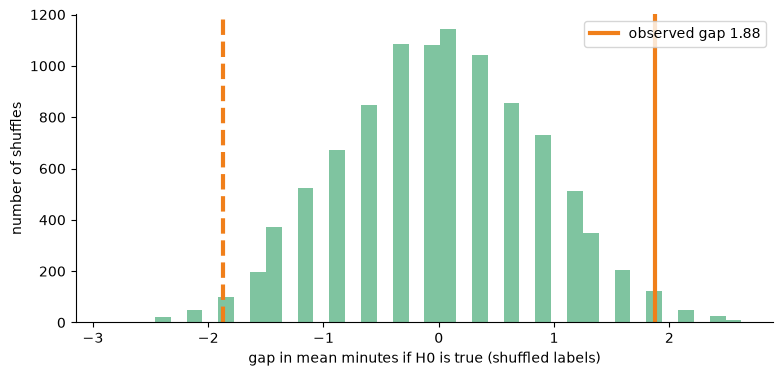

In [9]:
plt.hist(null_gaps, bins=40, color="#7fc4a0")
plt.axvline(observed_gap, color="#f07f1a", lw=3, label=f"observed gap {observed_gap:.2f}")
plt.axvline(-observed_gap, color="#f07f1a", lw=3, ls="--")
plt.xlabel("gap in mean minutes if H0 is true (shuffled labels)")
plt.ylabel("number of shuffles")
plt.legend()
plt.show()

### Type I and type II errors and power

| | H0 true | H0 false |
|---|---|---|
| Reject H0 | **type I error** (false alarm), probability α | correct, probability 1 − β, the **power** |
| Keep H0 | correct | **type II error** (missed effect), probability β |

In software terms, a type I error ships a model that is not better; a type II error drops a model that is better. We check both rates by simulation: many tests of two groups of 50 values each, first with no difference (the false-alarm rate should be close to α), then with a real difference of half a standard deviation (the share of rejections is the power). `stats.ttest_ind(..., equal_var=False)` is the Welch t-test of block 2.

**Predict.** With 50 values per group and a gap of half a standard deviation, is the power closer to 0.3, 0.7 or 0.95?

In [10]:
rng = np.random.default_rng(1)
runs = 2_000
false_alarms = 0
detections = 0
for _ in range(runs):
    group_a = rng.normal(0, 1, 50)
    same_as_a = rng.normal(0, 1, 50)
    shifted = rng.normal(0.5, 1, 50)
    false_alarms += stats.ttest_ind(group_a, same_as_a, equal_var=False).pvalue < 0.05
    detections += stats.ttest_ind(group_a, shifted, equal_var=False).pvalue < 0.05
print(f"false-alarm rate {false_alarms / runs:.3f}, power {detections / runs:.3f}")

false-alarm rate 0.047, power 0.706


### What a confidence interval promises

A 95 % confidence interval comes from a method that covers the true value in 95 % of repeated samples. One computed interval either covers it or not; the 95 % belongs to the method. We draw 100 samples of 400 requests with a true acceptance rate of 70 % and compute the **Wilson interval** of each with `proportion_confint(successes, n, method="wilson")`.

**Predict.** How many of the 100 intervals will miss 70 %?

In [11]:
rng = np.random.default_rng(1)
misses = 0
for _ in range(100):
    accepted = rng.binomial(400, 0.70)
    low, high = proportion_confint(accepted, 400, alpha=0.05, method="wilson")
    misses += not (low <= 0.70 <= high)
print(f"{misses} of 100 intervals miss the true rate")

5 of 100 intervals miss the true rate


The American Statistical Association summarised six principles for p-values ([Wasserstein and Lazar, 2016](https://doi.org/10.1080/00031305.2016.1154108)). Principle 2: "P-values do not measure the probability that the studied hypothesis is true, or the probability that the data were produced by random chance alone." Principle 5: "A p-value, or statistical significance, does not measure the size of an effect or the importance of a result."

> 📖 **Read more:** [extras/13-hypothesis-testing.ipynb](extras/13-hypothesis-testing.ipynb) and [extras/14-hypothesis-testing-by-simulation.ipynb](extras/14-hypothesis-testing-by-simulation.ipynb): the logic of a test by simulation.

## Choosing a test for a lifecycle question

Four questions about the data choose the test:

1. **One number, or a comparison?** One accuracy needs an interval; two models or versions need a test of the difference.
2. **The same rows, or different rows?** Both models score the same test rows: **paired**. Each request sees one version: **independent groups**.
3. **Who decided which unit got which version?** A coin (random assignment), or the calendar (before and after a release)?
4. **Yes/no, or a number?** Right or wrong, accepted or not: a proportion. Euros, minutes, reviews: a mean or a median.

| How the data were made | Yes/no outcome | Number outcome |
|---|---|---|
| The same rows, both versions (paired) | **McNemar's test** | **paired bootstrap**, Wilcoxon signed-rank, paired t-test |
| A random split (independent groups) | **two-proportion z-test**, chi-square, Fisher, Bayesian A/B | **Welch t-test**, Mann–Whitney, CUPED |
| Before and after, no random split | **difference-in-differences**, placebo dates | **counterfactual forecast**, difference-in-differences |

> **Quiz.** A new checkout page went live for everyone on 1 June, and orders per day rose. Which row of the table applies?

## Case 1 · Two models, one test set

### Step 1 · Background and the request

The customs-heading service of our final project suggests a four-digit heading for a product description. The team trained a second model, B, that also reads the keywords field of each decision. The product owner writes (an example written for this course): *"B is right on more test decisions than A. B is better, so let us switch on Monday. OK?"* With B, every customs officer must type keywords for each request, so the switch has a cost.

*Background reading:* [Card et al. (2020)](https://doi.org/10.18653/v1/2020.emnlp-main.745) found that many published gains of language models were smaller than their test sets could detect.

### Step 2 · The data: two predictions per decision

We train both models on German EBTI decisions issued before 15 April 2026 and test them on the decisions issued from that date. Both models are the same: TF-IDF features and a linear classifier (`SGDClassifier`), which we meet in Session 13. Only the text differs: A reads the description, B the description plus the keywords. The two fits take about a minute.

In [12]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import SGDClassifier

decisions = pd.read_parquet("case-study/data/ebti/decisions.parquet")
german = decisions[decisions["language"] == "de"].sort_values("date_of_issue")
cutoff = pd.Timestamp("2026-04-15")
train = german[german["date_of_issue"] < cutoff]
test = german[german["date_of_issue"] >= cutoff]
test_headings = test["heading"].to_numpy()
print(f"{len(train):,} training decisions, {len(test):,} test decisions")

53,671 training decisions, 9,573 test decisions


A function trains one model on a text column and returns its predictions for the test decisions. Keeping the code in one function makes sure both models are built the same way.

In [13]:
def train_and_predict(train_text: pd.Series, test_text: pd.Series) -> np.ndarray:
    """Fit TF-IDF and a linear classifier on the training texts; return the predicted headings of the test texts."""
    vectorizer = TfidfVectorizer(min_df=2, sublinear_tf=True)
    model = SGDClassifier(loss="hinge", alpha=2e-5, random_state=0)
    model.fit(vectorizer.fit_transform(train_text), train["heading"])
    return model.predict(vectorizer.transform(test_text))


with_keywords = lambda table: table["description"] + " " + table["keywords"].fillna("")
predictions_a = train_and_predict(train["description"], test["description"])
predictions_b = train_and_predict(with_keywords(train), with_keywords(test))

One row per test decision with both predictions is the table we test. `a_correct` and `b_correct` are Boolean arrays: True where the model suggested the true heading.

In [14]:
a_correct = predictions_a == test_headings
b_correct = predictions_b == test_headings
paired = pd.DataFrame({"heading": test_headings, "model_a": predictions_a, "model_b": predictions_b,
                       "a_correct": a_correct, "b_correct": b_correct})
paired.head()

,heading,model_a,model_b,a_correct,b_correct
0,8714,8714,8714,True,True
1,7019,7019,7019,True,True
2,8504,8504,8504,True,True
3,9505,9505,9505,True,True
4,8542,8542,8542,True,True


### Step 3 · An interval for each accuracy

An accuracy measured on n rows is uncertain. The normal (Wald) interval, the default of `proportion_confint`, is $\hat{p} \pm 1.96\sqrt{\hat{p}(1-\hat{p})/n}$; the **Wilson interval** is better near 0 % or 100 %, and statsmodels computes it.

**Predict.** Will the two intervals overlap?

In [15]:
for name, correct in [("A", a_correct), ("B", b_correct)]:
    low, high = proportion_confint(correct.sum(), len(correct), alpha=0.05, method="wilson")
    print(f"model {name}: accuracy {correct.mean():.2%}, 95 % interval [{low:.2%}, {high:.2%}]")

model A: accuracy 97.29%, 95 % interval [96.95%, 97.60%]
model B: accuracy 97.36%, 95 % interval [97.02%, 97.66%]


The intervals overlap almost completely. That is not a test of the difference: both models scored the **same** rows, and most rows are right for both. The next steps use the pairs.

### Step 4 · The disagreement table

Crossing the right/wrong column of A with that of B gives a 2 × 2 table. Rows where both are right or both are wrong say nothing about which model is better; only the **disagreements** do. `pd.crosstab(a, b)` counts every combination; with Boolean columns, False comes first.

In [16]:
table = pd.crosstab(a_correct, b_correct).to_numpy()
b, c = table[0, 1], table[1, 0]       # b: only B right; c: only A right
print(table)
print(f"only B right: b = {b}, only A right: c = {c}, accuracy gap = (b - c) / n = {100 * (b - c) / len(a_correct):+.3f} points")

[[ 222   37]
 [  31 9283]]
only B right: b = 37, only A right: c = 31, accuracy gap = (b - c) / n = +0.063 points


### McNemar's test by hand

Under H0 (both models equally accurate), each disagreement is a fair coin: only B right or only A right, each with probability ½. McNemar's statistic with the continuity correction is

$$\chi^{2} = \frac{\left(\left|b - c\right| - 1\right)^{2}}{b + c},$$

which follows a chi-square distribution with 1 degree of freedom under H0. The exact version is a binomial test of b out of b + c with probability ½ (`stats.binomtest`). First the toy numbers of the slides, b = 12 and c = 4:

In [17]:
toy_b, toy_c = 12, 4
toy_chi2 = (abs(toy_b - toy_c) - 1) ** 2 / (toy_b + toy_c)
print(f"chi2 = {toy_chi2:.2f}, p = {stats.chi2.sf(toy_chi2, 1):.3f}, exact p = {stats.binomtest(toy_c, toy_b + toy_c, 0.5).pvalue:.3f}")

chi2 = 3.06, p = 0.080, exact p = 0.077


**Predict.** Our case has b = 37 and c = 31. Is p below 0.05?

In [18]:
case_chi2 = (abs(b - c) - 1) ** 2 / (b + c)
print(f"chi2 = {case_chi2:.2f}, p = {stats.chi2.sf(case_chi2, 1):.2f}")

chi2 = 0.37, p = 0.54


### Step 5 · McNemar's test in statsmodels

`mcnemar(table, exact=True)` runs the exact binomial version on the 2 × 2 table; `exact=False, correction=True` gives the chi-square version above.

In [19]:
result = mcnemar(table, exact=True)
print(b, c, round(result.pvalue, 4))

37 31 0.5446


A common mistake is to treat the two accuracies as two independent samples and run a two-proportion z-test. Dietterich (1998) showed that this test "should never be used" for this job: it ignores the pairing.

In [20]:
z, p_unpaired = proportions_ztest([b_correct.sum(), a_correct.sum()], [len(b_correct), len(a_correct)])
print(f"unpaired z-test p = {p_unpaired:.2f} (wrong test for paired rows)")

unpaired z-test p = 0.79 (wrong test for paired rows)


### Paired bootstrap of the accuracy difference

The **paired bootstrap** works for any metric: draw the test rows with replacement, keep each row's pair of predictions together, and recompute the difference. The middle 95 % of the differences is the interval. `rng.integers(0, n, size=(k, n))` draws k samples of n row numbers at once.

In [21]:
rng = np.random.default_rng(0)
n_test = len(a_correct)
rows = rng.integers(0, n_test, size=(10_000, n_test))
boot_diff = b_correct[rows].mean(axis=1) - a_correct[rows].mean(axis=1)
low, high = np.percentile(boot_diff, [2.5, 97.5])
print(f"B - A = {100 * (b_correct.mean() - a_correct.mean()):+.3f} points, 95 % interval [{100 * low:+.3f}, {100 * high:+.3f}] points")

B - A = +0.063 points, 95 % interval [-0.104, +0.230] points


What do you see? The interval of the difference contains 0.

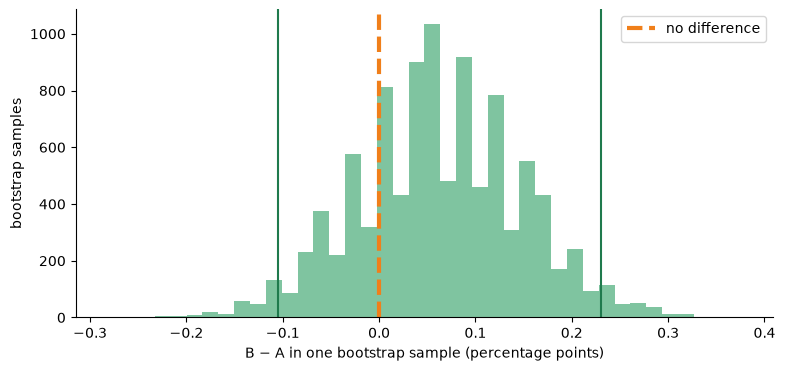

In [22]:
plt.hist(boot_diff * 100, bins=40, color="#7fc4a0")
plt.axvline(0, color="#f07f1a", lw=3, ls="--", label="no difference")
plt.axvline(low * 100, color="#1f7a4d"); plt.axvline(high * 100, color="#1f7a4d")
plt.xlabel("B − A in one bootstrap sample (percentage points)")
plt.ylabel("bootstrap samples")
plt.legend()
plt.show()

**Why this step?** Why must the bootstrap draw whole rows, with both predictions, instead of resampling A's and B's results separately?

### Regression models: paired errors

The same idea holds for regression: two price models predict the same listings, so each listing gives a pair of errors. We compare the absolute errors in euros with the **Wilcoxon signed-rank test** (`stats.wilcoxon`), the paired version of the rank test of block 2, and with a paired bootstrap of the difference in mean absolute error (MAE). Model 1 uses the number of guests only; model 2 adds the room type and the district. Prices are clipped at €1,000 to keep a few extreme listings from dominating.

In [23]:
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split

listings = pd.read_parquet("case-study/data/airbnb/listings.parquet")
priced = listings[listings["price"].between(10, 1000)].copy()
features_1 = pd.get_dummies(priced[["accommodates"]], dtype=float)
features_2 = pd.get_dummies(priced[["accommodates", "room_type", "district"]], dtype=float)
train_rows, test_rows = train_test_split(priced.index, test_size=0.3, random_state=0)

errors = {}
for name, features in [("model_1", features_1), ("model_2", features_2)]:
    model = LinearRegression().fit(features.loc[train_rows], priced.loc[train_rows, "price"])
    errors[name] = (priced.loc[test_rows, "price"] - model.predict(features.loc[test_rows])).abs().to_numpy()
print({name: round(e.mean(), 1) for name, e in errors.items()})

{'model_1': np.float64(69.2), 'model_2': np.float64(67.5)}


In [24]:
error_gap = errors["model_1"] - errors["model_2"]       # > 0 where model 2 is closer
print(stats.wilcoxon(errors["model_1"], errors["model_2"]))
rows = rng.integers(0, len(error_gap), size=(10_000, len(error_gap)))
mae_gap = error_gap[rows].mean(axis=1)
print(f"MAE gain of model 2: {error_gap.mean():.1f} euros, 95 % interval [{np.percentile(mae_gap, 2.5):.1f}, {np.percentile(mae_gap, 97.5):.1f}]")

WilcoxonResult(statistic=np.float64(884806.5), pvalue=np.float64(1.9844691344395406e-05))
MAE gain of model 2: 1.7 euros, 95 % interval [1.0, 2.4]


### Step 6 · The finding for the product owner

1. **The finding.** Model B is not measurably more accurate than model A on German decisions issued after 15 April 2026.
2. **One number with its context.** B is right on 6 more decisions out of 9,573 (+0.06 points); the 95 % interval of the difference runs from about −0.10 to +0.23 points, and McNemar's test gives p = 0.54.
3. **What it means for the decision.** Accuracy does not justify asking officers to type keywords. Decide on other grounds, or measure what officers do with the suggestions online (Case 2).
4. **One limitation.** German decisions only; a gain of up to about 0.2 points cannot be excluded with this test set.

> 📖 **Read more:** [Dietterich (1998)](https://doi.org/10.1162/089976698300017197), approximate statistical tests for comparing classifiers; [extras/18-fisher-exact-test.ipynb](extras/18-fisher-exact-test.ipynb) for exact tests on small tables.

## Case 2 · Two model versions online

### Step 1 · Background and the request

Case 1 found no accuracy gain offline, so the team now tests what offline accuracy cannot measure: how the suggestions are shown. Version 2 of the service shows the three most likely headings instead of one. Each incoming request goes at random to version 1 or version 2, and the service logs whether the officer accepts a suggested heading. The team lead wants to look at the dashboard every morning and roll out as soon as p < 0.05. The requests below are **simulated** (seed 7): the true acceptance rates are 70.0 % for version 1 and 71.5 % for version 2, which the team does not know.

*Background reading:* at Booking.com, offline gains of models did not predict gains in business metrics online ([Bernardi et al., 2019](https://doi.org/10.1145/3292500.3330744)).

### Step 2 · Plan the sample size

The number of requests per version depends on the smallest gain worth detecting (here 1.5 points, from 70 % to 71.5 %), α and the power:

$$n = \frac{\left(z_{1-\alpha/2} + z_{1-\beta}\right)^{2}\left[p_{1}(1-p_{1}) + p_{2}(1-p_{2})\right]}{\left(p_{2}-p_{1}\right)^{2}}$$

statsmodels solves it with `NormalIndPower().solve_power`, after turning the two rates into an effect size with `proportion_effectsize`.

**Predict.** How many requests per version: about 1,500, 15,000 or 150,000?

In [25]:
rate_v1, rate_v2_true = 0.70, 0.715
z_alpha, z_beta = stats.norm.ppf(0.975), stats.norm.ppf(0.8)
n_by_formula = (z_alpha + z_beta) ** 2 * (rate_v1 * (1 - rate_v1) + rate_v2_true * (1 - rate_v2_true)) / (rate_v2_true - rate_v1) ** 2
effect = proportion_effectsize(rate_v2_true, rate_v1)
n_per_version = int(np.ceil(NormalIndPower().solve_power(effect_size=effect, alpha=0.05, power=0.8, ratio=1.0)))
print(f"formula: {n_by_formula:,.0f}, statsmodels: {n_per_version:,} requests per version")

formula: 14,434, statsmodels: 14,436 requests per version


### Step 3 · Simulate the experiment

Each request gets a coin toss for its version (`rng.random(n) < 0.5`) and a yes/no outcome with the true rate of that version. `day` spreads the requests over 14 days.

In [26]:
rng = np.random.default_rng(7)
total_requests = 2 * n_per_version
in_v2 = rng.random(total_requests) < 0.5
accepted = rng.random(total_requests) < np.where(in_v2, rate_v2_true, rate_v1)
day = np.sort(rng.integers(0, 14, total_requests))
n_v1, n_v2 = int((~in_v2).sum()), int(in_v2.sum())
accepted_v1, accepted_v2 = int(accepted[~in_v2].sum()), int(accepted[in_v2].sum())
print(f"v1: {accepted_v1:,} of {n_v1:,} ({accepted_v1 / n_v1:.1%}); v2: {accepted_v2:,} of {n_v2:,} ({accepted_v2 / n_v2:.1%})")

v1: 10,193 of 14,560 (70.0%); v2: 10,260 of 14,312 (71.7%)


### Step 4 · The sample-ratio check

Before reading the result, check that the coin split the traffic as planned. A **sample-ratio mismatch (SRM)** means something in the system broke the randomization (a bot filter, a crash, a redirect), and the result cannot be trusted. `stats.chisquare(counts)` compares the counts with equal expected counts.

In [27]:
srm = stats.chisquare([n_v1, n_v2])
print(f"chi2 = {srm.statistic:.2f}, p = {srm.pvalue:.2f}")

chi2 = 2.13, p = 0.14


### Step 5 · The two-proportion z-test

$$z = \frac{\hat{p}_{2} - \hat{p}_{1}}{\sqrt{\hat{p}(1-\hat{p})\left(\frac{1}{n_{1}} + \frac{1}{n_{2}}\right)}}$$

with $\hat{p}$ the pooled rate. `proportions_ztest([successes_2, successes_1], [n_2, n_1])` returns z and the two-sided p-value. The interval of the gain uses each version's own rate.

In [28]:
z, p_value = proportions_ztest([accepted_v2, accepted_v1], [n_v2, n_v1])
gain = accepted_v2 / n_v2 - accepted_v1 / n_v1
standard_error = np.sqrt(accepted_v1 / n_v1 * (1 - accepted_v1 / n_v1) / n_v1 + accepted_v2 / n_v2 * (1 - accepted_v2 / n_v2) / n_v2)
print(f"z = {z:.2f}, p = {p_value:.4f}, gain {100 * gain:+.2f} points, 95 % interval [{100 * (gain - 1.96 * standard_error):+.2f}, {100 * (gain + 1.96 * standard_error):+.2f}] points")

z = 3.14, p = 0.0017, gain +1.68 points, 95 % interval [+0.63, +2.73] points


### Peeking at the p-value every day

The plan in the chat was to look every morning and stop at the first p < 0.05. Each look is another test. First the daily p-values of our experiment:

In [29]:
daily_p = []
for d in range(14):
    seen = day <= d
    _, p_day = proportions_ztest([accepted[seen & in_v2].sum(), accepted[seen & ~in_v2].sum()], [(seen & in_v2).sum(), (seen & ~in_v2).sum()])
    daily_p.append(p_day)
print(np.round(daily_p, 3))

[0.155 0.498 0.338 0.46  0.172 0.137 0.097 0.093 0.066 0.047 0.016 0.019
 0.008 0.002]


**Predict.** In an **A/A test** both versions are identical, so every "winner" is a false alarm. If a team looks every day for 14 days and stops at the first p < 0.05, how often does it find a winner: about 5 %, about 20 % or about 50 %?

In [30]:
rng = np.random.default_rng(11)
per_day = total_requests // 14
ever_below, below_at_end = 0, 0
for _ in range(2_000):
    successes = rng.binomial(per_day // 2, 0.70, size=(14, 2)).cumsum(axis=0)
    per_arm = (per_day // 2) * np.arange(1, 15)
    pooled = successes.sum(axis=1) / (2 * per_arm)
    z_day = (successes[:, 1] - successes[:, 0]) / per_arm / np.sqrt(pooled * (1 - pooled) * 2 / per_arm)
    p_day = 2 * stats.norm.sf(np.abs(z_day))
    ever_below += (p_day < 0.05).any()
    below_at_end += p_day[-1] < 0.05
print(f"stopped at some day: {ever_below / 2_000:.1%}; significant at the planned end: {below_at_end / 2_000:.1%}")

stopped at some day: 22.2%; significant at the planned end: 5.7%


A p-value is valid once, at the planned end. Teams that must look early use sequential tests with always-valid p-values ([Johari et al., 2017](https://arxiv.org/abs/1512.04922)).

### A Bayesian reading of the same test

With a flat prior, the posterior of each acceptance rate is $\operatorname{Beta}(1 + x, 1 + n - x)$, where x is the number of accepted requests. Drawing from both posteriors and counting how often version 2 is ahead gives P(v2 better | data), the question the team lead asks.

In [31]:
post_v1 = rng.beta(1 + accepted_v1, 1 + n_v1 - accepted_v1, 200_000)
post_v2 = rng.beta(1 + accepted_v2, 1 + n_v2 - accepted_v2, 200_000)
prob_v2_better = (post_v2 > post_v1).mean()
print(f"P(v2 better | data) = {prob_v2_better:.3f}; frequentist p = {p_value:.4f}")

P(v2 better | data) = 0.999; frequentist p = 0.0017


The two answers agree here because the data are many and the prior is flat. With a strong prior or few data they can differ, and the Bayesian answer depends on the prior.

### Variance reduction with CUPED

**CUPED** (Deng et al., 2013) reduces the noise of a metric with data from before the test. If each officer's handling time last month predicts this month's, we subtract the predicted part: $Y_{\text{adj}} = Y - \theta (X - \bar{X})$ with $\theta = \operatorname{cov}(X, Y) / \operatorname{var}(X)$. The mean difference stays the same; its standard error shrinks. Simulated example: 2,000 officers, a true gain of 0.3 minutes.

In [32]:
rng = np.random.default_rng(3)
before = rng.normal(10, 3, 2_000)                                     # minutes per request last month
in_v2_officer = rng.random(2_000) < 0.5
during = 0.8 * before + rng.normal(2, 1.5, 2_000) - 0.3 * in_v2_officer
theta = np.cov(before, during)[0, 1] / before.var(ddof=1)
adjusted = during - theta * (before - before.mean())
for name, y in [("raw", during), ("CUPED", adjusted)]:
    t = stats.ttest_ind(y[in_v2_officer], y[~in_v2_officer], equal_var=False)
    print(f"{name}: gap {y[in_v2_officer].mean() - y[~in_v2_officer].mean():+.3f} minutes, p = {t.pvalue:.4f}")

raw: gap -0.399 minutes, p = 0.0015
CUPED: gap -0.280 minutes, p = 0.0000


### Step 6 · The finding for the team lead

1. **The finding.** Officers accept more suggestions from version 2 than from version 1.
2. **One number with its context.** Acceptance rose from 70.0 % to 71.7 %, +1.7 points (95 % interval 0.6 to 2.7), over 28,872 simulated requests in 14 days; p = 0.0017; the split check gives p = 0.14.
3. **What it means for the decision.** Roll out version 2: it is better than version 1. The estimate is above the 1.5 points the team planned, but a gain as small as 0.6 points is also possible.
4. **One limitation.** Two weeks only: officers may accept more at first because the display is new. Check the rate again after a month.

> 📖 **Read more:** Kohavi, Tang and Xu (2020), *Trustworthy Online Controlled Experiments*, [Chapter 1 (free)](https://experimentguide.com/wp-content/uploads/TrustworthyOnlineControlledExperiments_PracticalGuideToABTesting_Chapter1.pdf).

## Case 3 · The dashboard metric after a release

### Step 1 · Background and the request

The host team of a rental platform released a review reminder to every guest in Berlin on 1 March 2026. The head of the team writes (an example): *"Since the reminder went live, reviews are up 55 %. Can you confirm it was the reminder?"* The reviews are real (Inside Airbnb, Berlin); **the reminder never existed**. Its true effect is therefore zero, and any method that finds an effect gives a false alarm.

*Background reading:* Card and Krueger (1994) compared New Jersey with Pennsylvania to measure the effect of a minimum wage ([NBER WP 4509](https://www.nber.org/papers/w4509)).

### Step 2 · The BI series: reviews per month

`reviews_monthly.parquet` holds one row per listing and month with the number of reviews. Summing by month gives the dashboard line. `.asfreq("MS")` gives the series a month-start frequency, which the time-series model needs.

In [33]:
reviews = pd.read_parquet("case-study/data/airbnb/reviews_monthly.parquet")
monthly_reviews = reviews.groupby("month")["n_reviews"].sum()["2022-01-01":"2026-05-01"].asfreq("MS")
print(monthly_reviews.tail(6))

month
2025-12-01     7577
2026-01-01     6113
2026-02-01     6407
2026-03-01     8262
2026-04-01     9057
2026-05-01    11799
Freq: MS, Name: n_reviews, dtype: int64


What do you see? Every winter the line falls, every spring it rises, and each year is higher than the last.

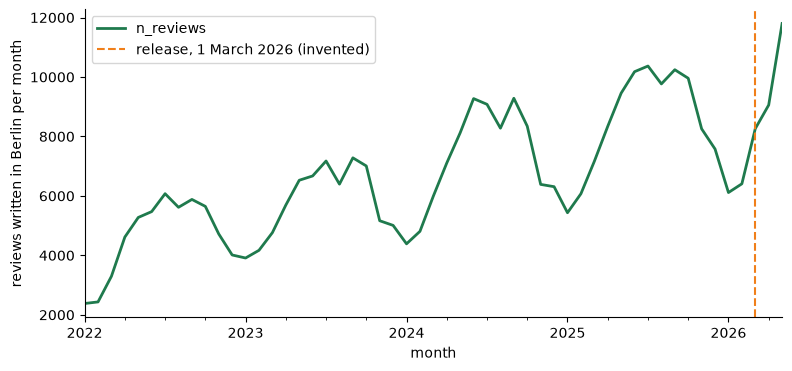

In [34]:
ax = monthly_reviews.plot(color="#1f7a4d", lw=2)
ax.axvline(pd.Timestamp("2026-03-01"), color="#f07f1a", ls="--", label="release, 1 March 2026 (invented)")
ax.set_xlabel("month"); ax.set_ylabel("reviews written in Berlin per month")
ax.legend(); plt.show()

Listings that left the platform before the snapshot are missing, so early years are undercounted: part of the upward trend comes from the data, not from the city.

### Step 3 · The before-and-after test without a control

The first analysis a busy team runs compares each listing's mean reviews per month in January and February with March to May, paired by listing (`stats.ttest_rel`). We run it for 2026 and, as a check, for 2025, a year without any release.

**Predict.** Will the 2025 test also be significant?

In [35]:
def before_after_test(year: int) -> None:
    """Paired t-test of each listing's mean monthly reviews, March to May against January and February."""
    rows = reviews[(reviews["month"] >= f"{year}-01-01") & (reviews["month"] <= f"{year}-05-01")]
    wide = rows.pivot_table(index="listing_id", columns="month", values="n_reviews", aggfunc="sum").fillna(0)
    before = wide[[m for m in wide.columns if m.month <= 2]].mean(axis=1)
    after = wide[[m for m in wide.columns if m.month >= 3]].mean(axis=1)
    test_ = stats.ttest_rel(after, before)
    print(f"{year}: {len(wide):,} listings, {before.mean():.2f} -> {after.mean():.2f} reviews per month, p = {test_.pvalue:.1e}")


before_after_test(2026)
before_after_test(2025)

2026: 4,577 listings, 1.37 -> 2.12 reviews per month, p = 1.1e-120
2025: 3,824 listings, 1.50 -> 2.18 reviews per month, p = 2.2e-106


Both years give a tiny p-value. The test answers "did reviews rise from winter to spring?", which they do every year. It cannot say whether the reminder caused anything.

### Step 4 · Last year as the control group

When a change reached everyone, the same months of an earlier year can serve as the control. We compute the spring rise (March to May over January and February) for each year and compare 2026 with 2025: a **difference-in-differences** with time as the control, as a ratio of ratios.

In [36]:
spring_rise = {}
for year in range(2022, 2027):
    spring_rise[year] = monthly_reviews[f"{year}-03-01":f"{year}-05-01"].mean() / monthly_reviews[f"{year}-01-01":f"{year}-02-01"].mean()
print({year: round(r, 3) for year, r in spring_rise.items()})
for year in (2023, 2024, 2025, 2026):
    print(f"{year} against {year - 1}: {spring_rise[year] / spring_rise[year - 1] - 1:+.1%}")

{2022: np.float64(1.826), 2023: np.float64(1.401), 2024: np.float64(1.539), 2025: np.float64(1.446), 2026: np.float64(1.55)}
2023 against 2022: -23.3%
2024 against 2023: +9.8%
2025 against 2024: -6.0%
2026 against 2025: +7.2%


The 2026 rise is about 7 % larger than that of 2025, while other years differ by −6 % to +10 % without any release (2023 against 2022 is left out: 2022 rose fast after the COVID-19 closures). A 7 % difference is an ordinary year.

### Difference-in-differences by hand: Card and Krueger

$$\hat{\delta} = \left(\bar{y}_{T,\text{after}} - \bar{y}_{T,\text{before}}\right) - \left(\bar{y}_{C,\text{after}} - \bar{y}_{C,\text{before}}\right)$$

Card and Krueger (1994, Table 3) report full-time-equivalent employees per fast-food restaurant: New Jersey (treated, new minimum wage) 20.44 in February and 21.03 in November 1992; Pennsylvania (control) 23.33 and 21.17.

In [37]:
new_jersey = (20.44, 21.03)
pennsylvania = (23.33, 21.17)
effect = (new_jersey[1] - new_jersey[0]) - (pennsylvania[1] - pennsylvania[0])
print(f"difference-in-differences: {effect:+.2f} employees per restaurant (the paper reports +2.76 from unrounded means)")

difference-in-differences: +2.75 employees per restaurant (the paper reports +2.76 from unrounded means)


The key assumption is **parallel trends**: without the change, the treated group would have moved like the control group.

### A control group with another season

Suppose the reminder had gone only to the four central districts, and a colleague uses the outer districts as the control. We compute the difference-in-differences for 2026 and for 2025, when there was no release.

**Predict.** If the method works, what should the 2025 result be?

In [38]:
listings = pd.read_parquet("case-study/data/airbnb/listings.parquet")
with_district = reviews.merge(listings[["id", "district"]].rename(columns={"id": "listing_id"}), on="listing_id")
central = ["Mitte", "Friedrichshain-Kreuzberg", "Pankow", "Neukölln"]
with_district["group"] = np.where(with_district["district"].isin(central), "central", "outer")
by_group = with_district.groupby(["month", "group"])["n_reviews"].sum().unstack()
for year in (2025, 2026):
    before = by_group.loc[f"{year}-01-01":f"{year}-02-01"].mean()
    after = by_group.loc[f"{year}-03-01":f"{year}-05-01"].mean()
    rise = after / before
    print(f"{year}: central x{rise['central']:.2f}, outer x{rise['outer']:.2f}, DiD {rise['central'] / rise['outer'] - 1:+.1%}")

2025: central x1.41, outer x1.55, DiD -8.9%
2026: central x1.51, outer x1.72, DiD -12.2%


Both years show almost the same negative gap: the outer districts rise more every spring. The trends are not parallel, so this control group would report a fall of about 12 % for a reminder that never existed. A placebo period before the change is the check.

### Step 5 · A counterfactual forecast

A **counterfactual forecast** fits a time-series model on the months before the change and forecasts the months after as if nothing had happened. Brodersen et al. (2015) built CausalImpact on this idea. We use `UnobservedComponents` of statsmodels with a local linear trend (`level="lltrend"`) and a 12-month season (`seasonal=12`) on the log of the reviews, so that the season acts as a factor. `get_forecast(steps=3)` forecasts March to May; `conf_int(alpha=0.05)` gives the 95 % band.

In [39]:
log_reviews = np.log(monthly_reviews)
before = log_reviews[:"2026-02-01"]
model = sm.tsa.UnobservedComponents(
    before, level="lltrend", seasonal=12)
fit = model.fit(disp=False)
forecast = fit.get_forecast(steps=3)
band = np.exp(forecast.conf_int(alpha=0.05))
actual = monthly_reviews["2026-03-01":"2026-05-01"]
effect = actual.sum() / np.exp(forecast.predicted_mean).sum() - 1
print(pd.DataFrame({"actual": actual.to_numpy(), "forecast": np.exp(forecast.predicted_mean).round(0).to_numpy(),
                    "low": band.iloc[:, 0].round(0).to_numpy(), "high": band.iloc[:, 1].round(0).to_numpy()}, index=actual.index))
print(f"March to May against the forecast: {effect:+.1%}")

            actual  forecast     low     high
month                                        
2026-03-01    8262    7894.0  6974.0   8936.0
2026-04-01    9057    9427.0  8106.0  10963.0
2026-05-01   11799   10698.0  8931.0  12814.0
March to May against the forecast: +3.9%


What do you see? The three observed months lie inside the 95 % band.

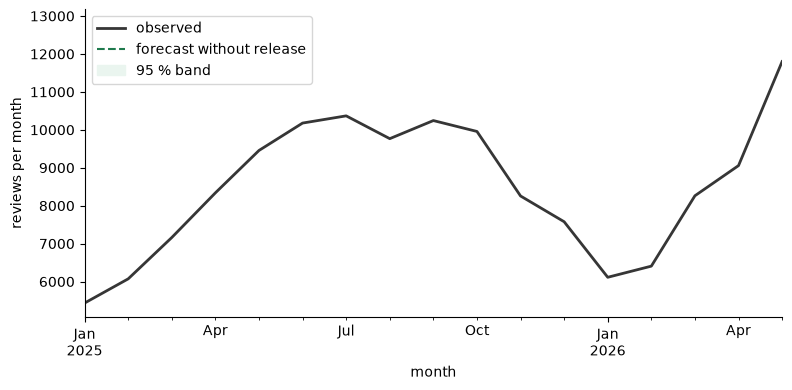

In [40]:
recent = monthly_reviews["2025-01-01":]
ax = recent.plot(color="#363636", lw=2, label="observed")
forecast_index = actual.index
ax.plot(forecast_index, np.exp(forecast.predicted_mean), color="#1f7a4d", ls="--", label="forecast without release")
ax.fill_between(forecast_index, band.iloc[:, 0], band.iloc[:, 1], color="#eaf5ef", label="95 % band")
ax.set_xlabel("month"); ax.set_ylabel("reviews per month"); ax.legend(); plt.show()

### Placebo tests

A **placebo test** runs the same method at a date with no change. If it often finds "effects" of the same size, the effect at the real date means little. We repeat the forecast for spring 2025.

In [41]:
fit_2025 = sm.tsa.UnobservedComponents(log_reviews[:"2025-02-01"], level="lltrend", seasonal=12).fit(disp=False)
forecast_2025 = fit_2025.get_forecast(steps=3)
actual_2025 = monthly_reviews["2025-03-01":"2025-05-01"]
print(f"placebo spring 2025: {actual_2025.sum() / np.exp(forecast_2025.predicted_mean).sum() - 1:+.1%}")

placebo spring 2025: -5.7%


### Step 6 · The finding for the host team

1. **The finding.** The rise in reviews after 1 March 2026 is the normal spring rise; we find no effect of the reminder.
2. **One number with its context.** Reviews rose ×1.55 from January–February to March–May, against ×1.45 a year earlier (+7 %; other years −6 % and +10 %). The three months lie inside the 95 % band of a forecast without the reminder (+3.9 %); the placebo year gives −5.7 %.
3. **What it means for the decision.** Leave the reminder out of the quarterly report as a success. To measure it, send it to a random half of the guests (Case 2).
4. **One limitation.** Monthly totals and one release date give little power: an added 5 % effect would stay inside the forecast band, and only at about 10 % do two of the three months leave it (exercise 3.4).

> 📖 **Read more:** Cunningham, *Causal Inference: The Mixtape*, [chapter 9, difference-in-differences](https://mixtape.scunning.com/09-difference_in_differences); [Brodersen et al. (2015)](https://doi.org/10.1214/14-AOAS788).

## Check your understanding

Vote alone, discuss with a neighbour, vote again.

1. A test of model B against model A gives p = 0.04. The probability that A and B are equally good is (A) 4 %, (B) 96 %, (C) below 5 %, (D) not computable from p alone.
2. Two classifiers are scored on the same 2,000 invoices. The right test is (A) a two-proportion z-test, (B) McNemar's test, (C) a Welch t-test on the two accuracies, (D) a chi-square test of model × right/wrong on 4,000 rows.
3. An A/A test is checked every day for 14 days and stopped at the first p < 0.05. A winner is "found" in about (A) 5 %, (B) 20 %, (C) 50 %, (D) 0 % of such tests.
4. A difference-in-differences with outer districts as control gives −12 % in the release year and −9 % in a year without a release. The best reading is (A) the release cut reviews by 12 %, (B) the groups have different seasons, (C) DiD cannot work, (D) the effect is −3 %.

## Exercises

Work in pairs; the lecturer picks which to set.

### 3.1 · Bayes' rule for a medical test

*Paper*

> 1 % of the women screened have breast cancer. The test finds 90 % of the cancers, and 9 % of the women without cancer also test positive. A woman tests positive. What is the probability that she has cancer? Answer first with natural frequencies (out of 1,000 women), then with Bayes' rule.

*Source:* Gigerenzer et al. (2007), [Helping doctors and patients make sense of health statistics](https://doi.org/10.1111/j.1539-6053.2008.00033.x).

*Your answer:*

### 3.2 · A smaller test set

*Code*

> The team can only check 1,000 decisions by hand. Draw 500 random test sets of 1,000 decisions from `a_correct` and `b_correct`, run McNemar's test on each, and count how often p < 0.05. Then count how often B looks ahead by at least 0.5 points. What does this mean for decisions taken on small test sets?

*Source:* course exercise, after Card et al. (2020).

### 3.3 · Plan a test for a smaller gain

*Code*

> The team now wants to detect a gain of 0.5 points (70.0 % to 70.5 %). How many requests per version are needed for a power of 0.8? How many days would that take at the traffic of the case (about 2,060 requests a day)?

*Source:* course exercise.

### 3.4 · Add a real effect to the series

*Code, pairs*

> Multiply the reviews of March to May 2026 by 1.10: a true effect of +10 %. Run the before-and-after test, the comparison with last year and the counterfactual forecast again. Which methods find the +10 %? Repeat with +5 % and +20 %. Hand in a table method × effect size and one sentence: the smallest effect this data can show.

*Hint.* Copy the series first: `monthly_reviews.copy()`, so the original stays unchanged.

*Source:* course exercise.

### 3.5 · Find the bug

*Find the bug*

> A colleague compares two models on the same test set with the code below. It runs without error. What is wrong, and what should the code be?
>
> ```python
> successes = [b_correct.sum(), a_correct.sum()]
> z, p_value = proportions_ztest(successes, [len(b_correct), len(a_correct)])
> print("B is better" if p_value < 0.05 else "no difference")
> ```

*Source:* course exercise, after Dietterich (1998).

*Your answer:*

## Debrief

- Compare two answers to exercise 3.2: how often did a small test set make B look better than it is?
- In exercise 3.4, look for the typical mistake: reading the before-and-after test's tiny p-value as proof of the injected effect, although it is just as tiny without it.
- Bridge to Session 6: regression output reports a p-value and an interval for every coefficient; the same reading applies.

## Further reading

- Orloff and Bloom, MIT 18.05, [Class 20: comparison of frequentist and Bayesian inference](https://ocw.mit.edu/courses/18-05-introduction-to-probability-and-statistics-spring-2022/mit18_05_s22_class20-prep.pdf).
- Wasserstein and Lazar (2016), [The ASA statement on p-values](https://doi.org/10.1080/00031305.2016.1154108).
- Dietterich (1998), [Approximate statistical tests for comparing supervised classification learning algorithms](https://doi.org/10.1162/089976698300017197).
- Card et al. (2020), [With little power comes great responsibility](https://doi.org/10.18653/v1/2020.emnlp-main.745).
- Bernardi, Mavridis and Estevez (2019), [150 successful machine learning models: 6 lessons learned at Booking.com](https://doi.org/10.1145/3292500.3330744).
- Kohavi, Tang and Xu (2020), [Trustworthy Online Controlled Experiments](https://doi.org/10.1017/9781108653985).
- Johari et al. (2017), [Peeking at A/B tests](https://arxiv.org/abs/1512.04922); Deng et al. (2013), [CUPED](https://doi.org/10.1145/2433396.2433413).
- Card and Krueger (1994), [Minimum wages and employment](https://www.nber.org/papers/w4509); Brodersen et al. (2015), [CausalImpact](https://doi.org/10.1214/14-AOAS788).
- Cunningham, [Causal Inference: The Mixtape](https://mixtape.scunning.com/), chapter 9.